# Part VI — KNN: the most similar situations of the past
**Method (sessions 14–15):** k-nearest neighbours, choice of k by cross-validation, comparison with logistic regression.
**Why:** KNN makes no assumption about the shape of the relationship, so it is a good **second opinion**. It also gives the most human explanation: *"in the 51 most similar starts since 2014, 38 scored points"*.

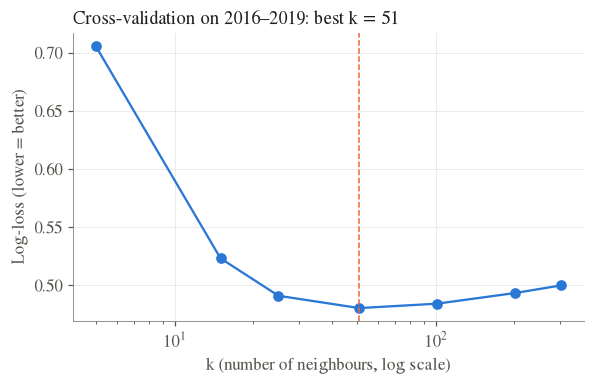

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1duel.data import build, TEAM_STATS
from f1duel.plots import style, title, save, BLUE, ORANGE, AQUA, GREY, INK, INK2, MUTED, TIER_COLORS
style(); pd.set_option('display.width', 140); pd.set_option('display.max_columns', 20)
d = build()
import json
from f1duel.model import CarProfile, AFTER_QUALI, nearest_cases
S = json.load(open('../results/summary.json'))
k_scores = {int(k): v for k, v in S['k_cv_logloss'].items()}
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(list(k_scores), list(k_scores.values()), 'o-', color=BLUE); ax.set_xscale('log')
ax.axvline(S['k'], color=ORANGE, ls='--', lw=1); ax.set_xlabel('k (number of neighbours, log scale)'); ax.set_ylabel('Log-loss (lower = better)')
title(ax, f"Cross-validation on 2016–2019: best k = {S['k']}"); save(fig, '06_choose_k'); plt.show()

**Bias–variance in one picture:** with k = 5 the model copies a handful of past cases (high variance); with k = 301 it averages almost everything (high bias). k = 51 is the best compromise, chosen **only** on 2016–2019.

In [2]:
rows = []
for t in ['2020-2025', '2026']:
    s = S[t]
    for m in ['Grid rule', 'Logistic regression', 'KNN']:
        g = s['gain_vs_grid'].get(m)
        rows.append({'Test': t, 'Method': m, 'Scorers named': round(s['scorers_named'][m], 2), 'ROC-AUC': round(s['auc'].get(m, np.nan), 3),
                     'Gain vs grid [95% CI]': '—' if g is None else f"{g[0]:+.2f} [{g[1]:+.2f}, {g[2]:+.2f}]"})
pd.DataFrame(rows).set_index(['Test', 'Method'])

Scorers named  ROC-AUC Gain vs grid [95% CI]
Test      Method                                                           
2020-2025 Grid rule                     7.71      NaN                     —
          Logistic regression           7.87    0.854  +0.16 [+0.02, +0.30]
          KNN                           7.80    0.848  +0.09 [-0.05, +0.23]
2026      Grid rule                     7.53      NaN                     —
          Logistic regression           7.59    0.852  +0.06 [-0.12, +0.24]
          KNN                           7.59    0.851  +0.06 [-0.18, +0.29]

**Reading:** KNN is close to logistic regression but slightly behind over 2020–2025 (its gain is not significant). With 8 features, distances become less informative (curse of dimensionality, session 14). We keep **logistic regression as the main model** and use KNN to **explain** a prediction.

### KNN as an explanation: the last race of our data (Singapore 2026)

In [3]:
past = d[(d.upcoming == 0) & ~((d.year == 2026) & (d['round'] == 17))]
prof = CarProfile().fit(past); tr = prof.transform(past)
race = prof.transform(d[(d.year == 2026) & (d['round'] == 17)])
for name in race.sort_values('grid').driver_name.iloc[[0, 9, 12]]:
    row = race[race.driver_name == name].iloc[0]
    nn = nearest_cases(tr, row, AFTER_QUALI, k=S['k'])
    print(f"{name:20s} started P{int(row.grid):<2d} | in the {S['k']} most similar past starts, {nn.top10.sum()} scored points ({nn.top10.mean():.0%}) "
          f"| real result: {'P' + str(int(row.finish_pos)) if row.finish_pos == row.finish_pos else 'DNF'}")

Max Verstappen       started P1  | in the 51 most similar past starts, 45 scored points (88%) | real result: P1
Nico Hülkenberg      started P10 | in the 51 most similar past starts, 26 scored points (51%) | real result: P8
Carlos Sainz Jr.     started P13 | in the 51 most similar past starts, 12 scored points (24%) | real result: P14
